# Bratley function


## 1. Setup


In [1]:
from pathlib import Path
import math
import sys

import matplotlib.pyplot as plt
import numpy as np
import torch

REPO_ROOT = Path.cwd().parent
sys.path.insert(0, str(REPO_ROOT))

from utilities.residual_orponet import ResidualOrPoNet
from utilities.function_library import bratley

from utilities.training import Trainer


In [2]:
DEVICE = torch.device("cpu")
DTYPE = torch.float32


torch.set_num_threads(1)


## 2. Data


In [3]:
DATASET_SEED = 1234
TRAIN_SAMPLES = 8000
VALIDATION_SAMPLES = 2000
TEST_SAMPLES = 2000


def build_dataset(dimension, seed):
    rng = np.random.default_rng(seed)
    physical_points = torch.from_numpy(
        rng.random((TRAIN_SAMPLES + VALIDATION_SAMPLES + TEST_SAMPLES, dimension))
    )
    targets = bratley(physical_points).to(DEVICE)
    inputs = (2 * physical_points - 1).to(dtype=DTYPE, device=DEVICE)
    validation_end = TRAIN_SAMPLES + VALIDATION_SAMPLES
    train_data = (inputs[:TRAIN_SAMPLES], targets[:TRAIN_SAMPLES])
    validation_data = (
        inputs[TRAIN_SAMPLES:validation_end],
        targets[TRAIN_SAMPLES:validation_end],
    )
    test_data = (inputs[validation_end:], targets[validation_end:])
    return train_data, validation_data, test_data


## 3. Model


In [4]:
DEGREE = 6
TORCH_SEED = 5678


def build_model(dimension, gain, seed):
    torch.manual_seed(seed)
    model = ResidualOrPoNet(
        basis_configs=[
            {"type": "hermite", "degree": DEGREE, "constant_channels": 2}
            for _ in range(dimension)
        ],
        data_domain_lb=[-1] * dimension,
        data_domain_ub=[1] * dimension,
        training_domain_lb=[-1] * dimension,
        training_domain_ub=[1] * dimension,
        neuron_copies=1,
        normalize_basis=True,
        use_additive_basis_branch=True,
        gate_config=None,
        dtype=DTYPE,
    ).to(DEVICE)

    # Match Figure 7's initial draws, without adding an initialization mode to the model.
    # Basis-aware initialization replaces multiplicative/output weights, but not additive weights.
    torch.manual_seed(seed)
    with torch.no_grad():
        for layer in model._hidden_layers[1:]:
            for weight in [layer.projection_w, layer.basis_projection]:
                weight.copy_(
                    torch.randn_like(weight) * (gain / math.sqrt(weight.shape[0]))
                )
        weight = model._output_weight
        weight.copy_(
            torch.randn_like(weight)
            * (gain / math.sqrt(weight.shape[1] * weight.shape[2]))
        )
    return model


## 4. Training


In [5]:
def run_dimension(dimension, run_index=0):
    # Offset both seeds for independent, reproducible repeats; run 0 keeps the defaults.
    dataset_seed = DATASET_SEED + run_index
    torch_seed = TORCH_SEED + run_index
    gain = 0.1 if dimension <= 500 else 0.01
    train_data, validation_data, test_data = build_dataset(dimension, dataset_seed)
    train_x, train_y = train_data
    validation_x, validation_y = validation_data
    target_mean = train_y.mean()
    target_std = train_y.std(unbiased=False)
    if target_std <= 0:
        raise ValueError("Training targets must have nonzero variance.")
    standardized_train_y = ((train_y - target_mean) / target_std).to(DTYPE)
    standardized_validation_y = ((validation_y - target_mean) / target_std).to(DTYPE)
    model = build_model(dimension, gain, torch_seed)
    optimizer = torch.optim.AdamW(model.parameters(), lr=0.001, weight_decay=1e-6)
    generator = torch.manual_seed(torch_seed)
    train_loader = torch.utils.data.DataLoader(
        torch.utils.data.TensorDataset(train_x, standardized_train_y),
        batch_size=256,
        shuffle=True,
        drop_last=True,
        generator=generator,
    )
    validation_loader = torch.utils.data.DataLoader(
        torch.utils.data.TensorDataset(validation_x, standardized_validation_y),
        batch_size=100,
        shuffle=False,
    )
    trainer = Trainer(
        model,
        (train_x, train_y),
        (validation_x, validation_y),
        target_stats=(target_mean, target_std),
        selection="validation_loss",
        validation_batches=validation_loader,
    )
    trainer.fit(
        optimizer,
        epochs=500,
        batches=train_loader,
        initialize=lambda first_batch: model.apply_basis_aware_init(
            first_batch, gain=gain
        ),
        early_stopping={"patience": 10, "grace": 20},
        log_every=25,
    )
    trainer.restore_best()
    test_x, test_y = test_data
    with torch.no_grad():
        prediction = model(test_x).double() * target_std + target_mean
        relative_mse = (
            (prediction - test_y).square().sum() / test_y.square().sum()
        ).item()
    return relative_mse


In [6]:
DIMENSIONS = [100, 250, 500, 750, 1000, 2000]
NUM_RUNS = 1


if NUM_RUNS < 1:
    raise ValueError("NUM_RUNS must be at least 1.")

plot_dimensions = []
test_relative_mse = []
for dimension in DIMENSIONS:
    for run_index in range(NUM_RUNS):
        print(
            f"Training Bratley: {dimension}D, run {run_index + 1}/{NUM_RUNS}",
            flush=True,
        )
        error = run_dimension(dimension, run_index)
        plot_dimensions.append(dimension)
        test_relative_mse.append(error)
        print(f"{dimension}D: test relative MSE={error:.3e}", flush=True)


Training Bratley: 100D, run 1/1


adamw 1: validation MSE=1.270e-02


adamw 25: validation MSE=4.506e-04


adamw 50: validation MSE=1.587e-04


adamw 75: validation MSE=9.038e-05


adamw 100: validation MSE=8.324e-05


... (32 outputs left out)

Training Bratley: 2000D, run 1/1


adamw 1: validation MSE=5.392e-02


adamw 25: validation MSE=2.849e-03


2000D: test relative MSE=1.653e-02


## 5. Dimension versus test error


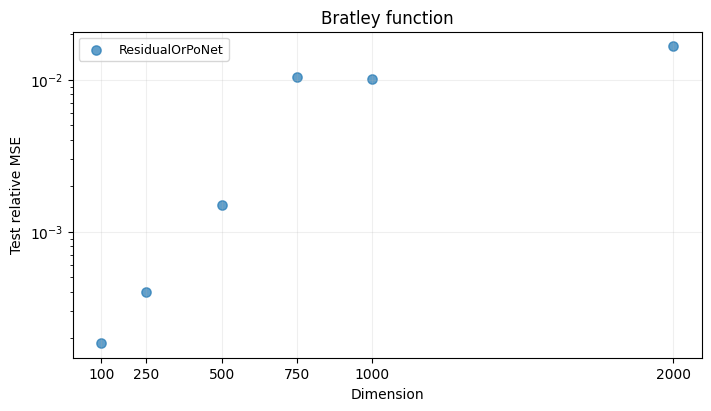

In [7]:
fig, ax = plt.subplots(figsize=(7, 4), constrained_layout=True)
ax.scatter(plot_dimensions, test_relative_mse, s=45, alpha=0.7, label="ResidualOrPoNet")
ax.set_yscale("log")
ax.set_xticks(DIMENSIONS)
ax.set(xlabel="Dimension", ylabel="Test relative MSE", title="Bratley function")
ax.grid(alpha=0.2)
ax.legend(fontsize=9)
plt.show()
